# Statistics of War: A Probability & Statistics Lab Project

This notebook analyses two centuries of armed conflict with every technique from the lab syllabus.
Each section maps to one lab topic:

| Lab | Topic | What we test on war data |
|---|---|---|
| 1–2 | Data import, descriptive statistics, graphs | War frequencies, casualty distributions, average duration, histograms, a world map |
| 3 | Correlation and simple regression | Conflict duration vs casualties; military burden vs GDP growth |
| 4 | Multiple regression | Predicting (log) casualties from several war characteristics |
| 5 | Binomial distribution | Do war initiators win? Do governments win civil wars? |
| 6 | Normal and Poisson distributions | Is log-casualties normal? Are yearly war onsets Poisson? |
| 7–8 | Hypothesis testing | Comparing outcomes and economic indicators across conflict groups |
| 9 | Independent and paired t-tests | Internationalised vs domestic civil wars; pre-war vs wartime GDP growth |
| 10 | Chi-square | Association between conflict type / era and outcome |
| 11 | ANOVA | Mean log-casualties across three war types |

**Data sources** (all public, downloaded into `data/raw/`):

* **Correlates of War (COW)** Inter-State War data v4 and Intra-State War data v4.1 — war names, years, participants, initiators, outcomes, battle deaths (1816–2007). Taken from the `peacesciencer` R package's copies (Miller 2022), which store them in country-year form.
* **COW National Material Capabilities** v6 — military expenditure (thousands of current USD), 1816–2016.
* **UCDP/PRIO Armed Conflict Dataset** — every armed conflict with ≥25 battle deaths per year, 1946 onwards; and UCDP conflict-onset counts.
* **Maddison Project Database 2020** (Bolt & van Zanden) via Our World in Data — real GDP and population, used for GDP growth.
* **World Bank WDI** GDP in current USD (via the `datasets/gdp` mirror) — the denominator for military burden (military spending as % of GDP).
* **Natural Earth** 1:110m country boundaries for the map.

Significance level throughout: **α = 0.05**.

In [1]:
%pip install jinja2 pyreadr country_converter geopandas scipy statsmodels matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

from pathlib import Path
import numpy as np
import pandas as pd
import pyreadr
import country_converter as coco
import matplotlib.pyplot as plt
import matplotlib as mpl
import geopandas as gpd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import lilliefors

ROOT = Path("/mnt/project-files/war-stats-project")
RAW, CLEAN, FIG = ROOT / "data/raw", ROOT / "data/clean", ROOT / "figures"
CLEAN.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# Chart style: one consistent palette (blue / orange / aqua / yellow), recessive grid
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"]
GRAY = "#8a8985"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.prop_cycle": mpl.cycler(color=PAL),
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelcolor": "#3a3936",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
    "lines.linewidth": 2,
})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show()

def verdict(p, alpha=0.05):
    return f"p = {p:.4g} → {'reject H0' if p < alpha else 'fail to reject H0'} at α = {alpha}"

## Lab 1–2 · Data import and cleaning

The COW files come in *country-year* form (one row per country per war-year). We collapse them to two analysis tables:

* **`wars`** — one row per war: type, start/end year, duration, total battle deaths, number of states, outcome.
* **`participants`** — one row per state per inter-state war: initiator flag, outcome (win/loss/other), the state's own battle deaths.

COW codes missing values as negative numbers (−9 unknown, −8 not applicable); these become `NaN`.

In [3]:
from pathlib import Path
import urllib.request
import pyreadr, pandas as pd

ROOT = Path.home() / "Downloads" / "war-stats-project" / "war-stats-project"
RAW, CLEAN, FIG = ROOT / "data/raw", ROOT / "data/clean", ROOT / "figures"
for p in (RAW, CLEAN, FIG):
    p.mkdir(parents=True, exist_ok=True)

RDA = ["cow_war_inter", "cow_war_intra", "ucdp_acd", "ucdp_onsets", "cow_nmc", "cow_states"]
CSV = ["maddison_2020_owid.csv", "wb_gdp_current_usd.csv"]

# download any missing .rda file from the peacesciencer R package
for name in RDA:
    f = RAW / f"{name}.rda"
    if not f.exists():
        url = f"https://github.com/svmiller/peacesciencer/raw/master/data/{name}.rda"
        try:
            urllib.request.urlretrieve(url, f); print("downloaded", f.name)
        except Exception as e:
            print("could not download", f.name, "->", e)

missing = [n for n in [f"{r}.rda" for r in RDA] + CSV if not (RAW / n).exists()]
if missing:
    raise FileNotFoundError(f"Missing in {RAW}: {missing}")

read = lambda name: pyreadr.read_r(RAW / f"{name}.rda")[name]
inter_raw, intra_raw = read("cow_war_inter"), read("cow_war_intra")
acd, onsets, nmc, states = read("ucdp_acd"), read("ucdp_onsets"), read("cow_nmc"), read("cow_states")
maddison = pd.read_csv(RAW / "maddison_2020_owid.csv")
wb_gdp = pd.read_csv(RAW / "wb_gdp_current_usd.csv")
for n, d in {"COW inter-state (dyad-years)": inter_raw, "COW intra-state (side-years)": intra_raw,
             "UCDP armed conflicts (conflict-years)": acd, "COW material capabilities": nmc,
             "Maddison GDP": maddison, "World Bank GDP": wb_gdp}.items():
    print(f"{n:40s} {d.shape[0]:>6,} rows × {d.shape[1]} cols")

COW inter-state (dyad-years)              1,932 rows × 15 cols
COW intra-state (side-years)              1,361 rows × 17 cols
UCDP armed conflicts (conflict-years)     5,652 rows × 15 cols
COW material capabilities                17,121 rows × 9 cols
Maddison GDP                             21,854 rows × 5 cols
World Bank GDP                           13,979 rows × 4 cols


In [4]:
neg_to_nan = lambda s: s.where(s >= 0)

# ---- inter-state wars: participant level ----
ir = inter_raw.copy()
ir["batdeath1"] = neg_to_nan(ir["batdeath1"])
participants = (ir.groupby(["warnum", "ccode1"])
                  .agg(start=("year", "min"), end=("year", "max"), initiator=("initiator1", "max"),
                       outcome_code=("outcome1", "first"), deaths=("batdeath1", "max"), side=("sidea1", "first"))
                  .reset_index().rename(columns={"ccode1": "ccode"}))
participants["outcome"] = participants.outcome_code.map({1: "Win", 2: "Loss"}).fillna("Other")
names = states.drop_duplicates("ccode").set_index("ccode")["statenme"]
participants["country"] = participants.ccode.map(names)

inter_wars = (participants.groupby("warnum")
              .agg(start=("start", "min"), end=("end", "max"), deaths=("deaths", lambda s: s.sum(min_count=1)),
                   n_states=("ccode", "nunique")).reset_index())
inter_wars["type"] = "Inter-state"

# ---- intra-state (civil) wars: war level ----
xr = intra_raw.copy()
xr["sideadeaths"], xr["sidebdeaths"] = neg_to_nan(xr.sideadeaths), neg_to_nan(xr.sidebdeaths)
deaths_a = xr.groupby(["warnum", "ccodea"]).sideadeaths.max().groupby("warnum").sum(min_count=1)
deaths_b = xr.groupby(["warnum", "sideb"]).sidebdeaths.max().groupby("warnum").sum(min_count=1)
prim = xr[xr.primary_state == 1]
intra_wars = (xr.groupby("warnum")
              .agg(name=("warname", "first"), subtype=("wartype", "first"), start=("year", "min"), end=("year", "max"),
                   intnl=("intnl", "max"), outcome_code=("outcome", "first"))
              .reset_index())
intra_wars["gov_ccode"] = intra_wars.warnum.map(prim.groupby("warnum").ccodea.first())
intra_wars["deaths"] = intra_wars.warnum.map(pd.concat([deaths_a, deaths_b], axis=1).sum(axis=1, min_count=1))
intra_wars["type"] = "Civil: " + intra_wars.subtype.str.replace("central control", "central control").str.replace("local issues", "local issues")
# outcome from the government's point of view (side A is the government in COW intra-state data)
intra_wars["outcome"] = intra_wars.outcome_code.map({1: "Government wins", 2: "Rebels win", 3: "Compromise"}).fillna("Other / unresolved")

# ---- combined war table ----
wars = pd.concat([inter_wars, intra_wars], ignore_index=True)
wars["duration"] = wars.end - wars.start + 1             # calendar years in which the war was active
# COW only records wars with ≥1,000 battle deaths; a smaller total means some sides' deaths are unknown, so treat it as missing
wars["deaths"] = wars.deaths.where(wars.deaths >= 1000)
wars["log_deaths"] = np.log10(wars.deaths)
wars["log_duration"] = np.log10(wars.duration)
wars["era"] = pd.cut(wars.start, [1800, 1899, 1945, 2100], labels=["1816–1899", "1900–1945", "1946–2007"])
MAJOR = {2, 200, 220, 255, 300, 325, 365, 710, 740}       # COW major powers (USA, UK, France, Germany, Austria-Hungary, Italy, Russia, China, Japan)
major_inter = participants.groupby("warnum").ccode.apply(lambda s: bool(set(s) & MAJOR))
wars["major_power"] = np.where(wars.type == "Inter-state", wars.warnum.map(major_inter), wars.gov_ccode.isin(MAJOR)).astype(int)
wars["type"] = pd.Categorical(wars.type, ["Inter-state", "Civil: central control", "Civil: local issues"])

wars.to_csv(CLEAN / "wars.csv", index=False); participants.to_csv(CLEAN / "interstate_participants.csv", index=False)
print(f"{len(wars)} wars ({(wars.type=='Inter-state').sum()} inter-state, {(wars.type!='Inter-state').sum()} civil), "
      f"{wars.deaths.notna().sum()} with known battle deaths")
wars.sample(5, random_state=1)[["warnum", "name", "type", "start", "end", "duration", "deaths", "n_states", "era"]]

401 wars (95 inter-state, 306 civil), 277 with known battle deaths


,warnum,name,type,start,end,duration,deaths,n_states,era
162,595.000,Bolivia-Criollos,Civil: central control,"1,870.000","1,871.000",2.000,NaN,NaN,1816–1899
333,842.000,South Yemen,Civil: central control,"1,986.000","1,986.000",1.000,"13,000.000",NaN,1946–2007
399,940.000,Second Sri Lanka Tamil,Civil: local issues,"2,006.000","2,007.000",2.000,NaN,NaN,1946–2007
117,533.000,"Second Syrian, Phase 1",Civil: local issues,"1,839.000","1,839.000",1.000,"3,000.000",NaN,1816–1899
80,193.000,NaN,Inter-state,"1,979.000","1,979.000",1.000,"21,000.000",2.000,1946–2007


## Lab 1–2 · Descriptive statistics

### War frequencies

Wars by type and era (counts):


era,1816–1899,1900–1945,1946–2007,All
type,,,,
Inter-state,29,28,38,95
Civil: central control,48,33,93,174
Civil: local issues,50,19,63,132
All,127,80,194,401


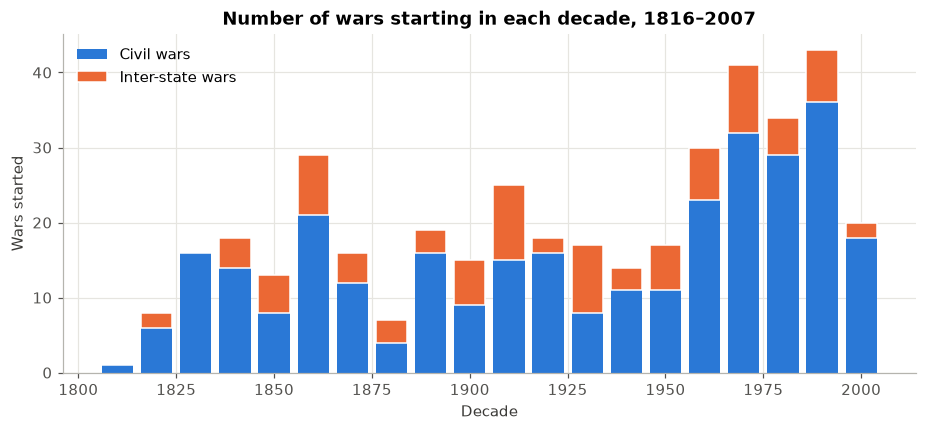

In [5]:
print("Wars by type and era (counts):")
display(pd.crosstab(wars.type, wars.era, margins=True))

decade = (wars.start // 10 * 10)
freq = pd.crosstab(decade, wars.type.astype(str).str.startswith("Civil").map({True: "Civil", False: "Inter-state"}))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(freq.index, freq["Civil"], width=8, color=PAL[0], label="Civil wars")
ax.bar(freq.index, freq["Inter-state"], width=8, bottom=freq["Civil"] , color=PAL[1], label="Inter-state wars",
       edgecolor="white", linewidth=1)
ax.set(title="Number of wars starting in each decade, 1816–2007", xlabel="Decade", ylabel="Wars started")
ax.legend(loc="upper left"); save(fig, "01_wars_per_decade")

**Interpretation.** The data hold 401 wars between 1816 and 2007: 95 inter-state and 306 civil wars. Civil wars outnumber wars between states in every era, and the number of civil wars rose sharply after 1945 with decolonisation and the Cold War.

### Casualty and duration distributions

In [6]:
def describe(s):
    s = s.dropna()
    return pd.Series({"n": len(s), "mean": s.mean(), "median": s.median(), "std": s.std(), "min": s.min(),
                      "Q1": s.quantile(.25), "Q3": s.quantile(.75), "max": s.max(), "skewness": s.skew(), "kurtosis": s.kurt()})

print("Battle deaths per war:")
display(wars.groupby("type", observed=True).deaths.apply(describe).unstack().style.format("{:,.1f}"))
print("Duration (calendar years) per war:")
display(wars.groupby("type", observed=True).duration.apply(describe).unstack().style.format("{:,.2f}"))
print(f"Average duration of all wars: {wars.duration.mean():.2f} years (median {wars.duration.median():.0f})")
print("\nDeadliest wars in the data:")
top = wars.nlargest(8, "deaths")[["warnum", "name", "type", "start", "end", "deaths"]]
top["name"] = top.name.fillna(top.warnum.map({139: "World War II", 106: "World War I", 151: "Korean War", 163: "Vietnam War, Phase 2",
                                              199: "Iran–Iraq War", 130: "Second Sino-Japanese War"}))
display(top)

Battle deaths per war:


,n,mean,median,std,min,Q1,Q3,max,skewness,kurtosis
type,,,,,,,,,,
Inter-state,95.0,"336,995.4","8,000.0","1,907,914.9","1,000.0","2,235.0","25,250.0","16,569,007.0",7.6,60.3
Civil: central control,99.0,"44,619.0","3,600.0","158,236.8","1,000.0","2,000.0","15,075.0","1,200,000.0",5.6,34.7
Civil: local issues,83.0,"19,792.7","6,330.0","68,218.8","1,000.0","2,100.0","18,500.0","618,000.0",8.4,74.5


Duration (calendar years) per war:


,n,mean,median,std,min,Q1,Q3,max,skewness,kurtosis
type,,,,,,,,,,
Inter-state,95.00,2.16,2.00,1.79,1.00,1.00,2.00,11.00,2.60,8.02
Civil: central control,174.00,3.21,2.00,3.39,1.00,1.00,4.00,23.00,3.04,11.83
Civil: local issues,132.00,3.72,2.00,3.76,1.00,2.00,4.00,20.00,2.38,5.83


Average duration of all wars: 3.13 years (median 2)

Deadliest wars in the data:


,warnum,name,type,start,end,deaths
54,139.000,World War II,Inter-state,"1,939.000","1,945.000","16,569,007.000"
38,106.000,World War I,Inter-state,"1,914.000","1,918.000","8,578,031.000"
81,199.000,Iran–Iraq War,Inter-state,"1,980.000","1,988.000","1,250,000.000"
245,725.000,"Chinese Civil War, Phase 2",Civil: central control,"1,946.000","1,950.000","1,200,000.000"
66,163.000,"Vietnam War, Phase 2",Inter-state,"1,965.000","1,975.000","1,021,442.000"
51,130.000,Second Sino-Japanese War,Inter-state,"1,937.000","1,941.000","1,000,000.000"
59,151.000,Korean War,Inter-state,"1,950.000","1,953.000","910,084.000"
214,677.000,Russian Civil War,Civil: central control,"1,917.000","1,921.000","802,225.000"


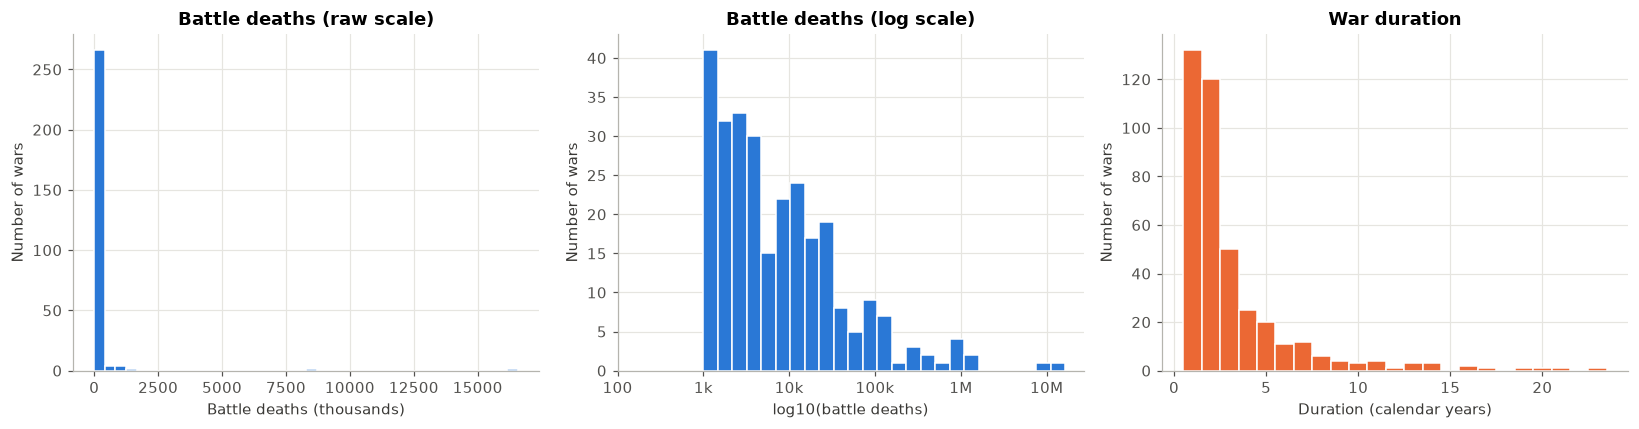

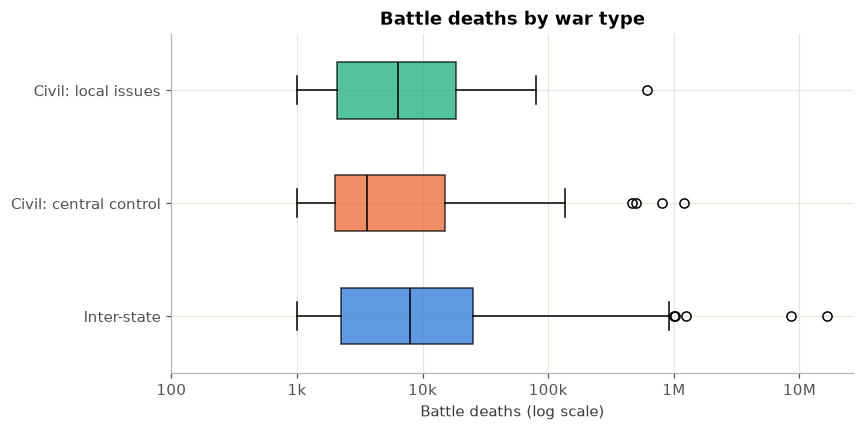

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
d = wars.deaths.dropna()
axes[0].hist(d / 1e3, bins=40, color=PAL[0], edgecolor="white")
axes[0].set(title="Battle deaths (raw scale)", xlabel="Battle deaths (thousands)", ylabel="Number of wars")
axes[1].hist(wars.log_deaths.dropna(), bins=25, color=PAL[0], edgecolor="white")
axes[1].set(title="Battle deaths (log scale)", xlabel="log10(battle deaths)", ylabel="Number of wars")
axes[1].set_xticks(range(2, 8)); axes[1].set_xticklabels(["100", "1k", "10k", "100k", "1M", "10M"])
axes[2].hist(wars.duration, bins=np.arange(0.5, wars.duration.max() + 1.5), color=PAL[1], edgecolor="white")
axes[2].set(title="War duration", xlabel="Duration (calendar years)", ylabel="Number of wars")
fig.tight_layout(); save(fig, "02_histograms_deaths_duration")

fig, ax = plt.subplots(figsize=(8, 4))
groups = [wars.loc[wars.type == t, "log_deaths"].dropna() for t in wars.type.cat.categories]
bp = ax.boxplot(groups, vert=False, patch_artist=True, widths=0.5, medianprops=dict(color="black"))
for patch, col in zip(bp["boxes"], PAL): patch.set_facecolor(col); patch.set_alpha(.75)
ax.set_yticks([1, 2, 3], wars.type.cat.categories)
ax.set_xticks(range(2, 8), ["100", "1k", "10k", "100k", "1M", "10M"])
ax.set(title="Battle deaths by war type", xlabel="Battle deaths (log scale)"); save(fig, "03_boxplot_deaths_by_type")

**Interpretation.** The average war lasts about **3.1 calendar years** (median 2). The *mean* battle-death figure is far above the *median* because a handful of wars (World War II ≈ 16.6 million, World War I ≈ 8.6 million) pull it up. For skewed data like this the median and IQR describe a "typical" war better than the mean and SD.

Battle deaths are **extremely right-skewed** (skewness far above 0): most wars kill a few thousand people, while the two World Wars kill millions. On a log scale the distribution becomes roughly symmetric, so the rest of the notebook models **log10(battle deaths)**.

### Post-1945 armed conflicts (UCDP)
UCDP uses a much lower threshold (25 battle deaths a year) than COW (1,000), so it counts many more conflicts.

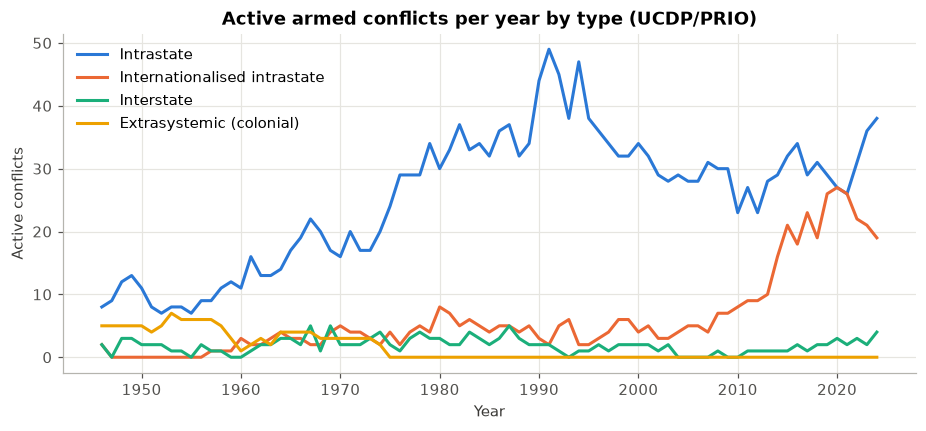

type_of_conflict  II  extrasystemic  interstate  intrastate
year                                                       
1,946.000          2              5           2           8
1,970.000          5              3           2          16
1,991.000          2              0           2          49
2,000.000          4              0           2          34
2,010.000          8              0           0          23
2,024.000         19              0           4          38


In [8]:
ucdp_year = acd.groupby(["year", "type_of_conflict"]).conflict_id.nunique().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4))
order = {"intrastate": "Intrastate", "II": "Internationalised intrastate", "interstate": "Interstate", "extrasystemic": "Extrasystemic (colonial)"}
for col, (cname, label) in zip(PAL, order.items()):
    ax.plot(ucdp_year.index, ucdp_year[cname], color=col, label=label)
ax.set(title="Active armed conflicts per year by type (UCDP/PRIO)", xlabel="Year", ylabel="Active conflicts")
ax.legend(); save(fig, "04_ucdp_conflicts_per_year")
print(ucdp_year.loc[[1946, 1970, 1991, 2000, 2010, ucdp_year.index.max()]])

### Map: how often each country has fought
Inter-state war participations plus civil wars in which the country's government was the primary combatant (1816–2007). Historical states are mapped to their modern successor (e.g. Prussia → Germany, Austria-Hungary → Austria).

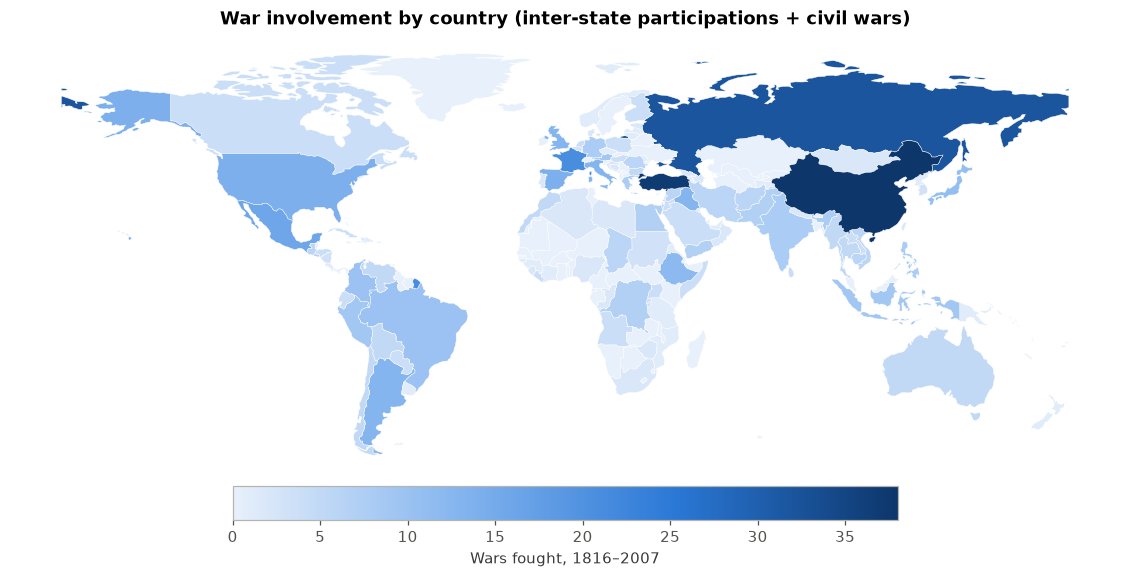

Most war-involved countries:
China             38
Türkiye           37
Russia            32
France            21
Mexico            16
Spain             14
United States     14
Italy             13
Argentina         13
United Kingdom    13


In [9]:
def to_iso3(ccodes):
    nm = pd.Series(ccodes).map(names)
    iso = coco.convert(nm.fillna("xx").tolist(), to="ISO3", not_found=None)
    iso = [i[0] if isinstance(i, list) else i for i in iso]
    return pd.Series(iso, index=pd.Series(ccodes).index).replace({"xx": np.nan})

ccode_iso = pd.Series(sorted(set(states.ccode)))
ccode_iso = pd.Series(to_iso3(ccode_iso).values, index=ccode_iso.values)
counts = pd.concat([participants.ccode, intra_wars.gov_ccode.dropna()]).map(ccode_iso).value_counts()
world = gpd.read_file(RAW / "ne_110m_countries.geojson")
world = world[world.ADM0_A3 != "ATA"]
world["wars"] = world.ADM0_A3.map(counts).fillna(0)

fig, ax = plt.subplots(figsize=(13, 6.5))
world.plot(column="wars", cmap=mpl.colors.LinearSegmentedColormap.from_list("b", ["#e8f0fb", "#86b6ef", "#2a78d6", "#0d366b"]),
           linewidth=0.3, edgecolor="white", ax=ax, legend=True,
           legend_kwds={"label": "Wars fought, 1816–2007", "shrink": 0.6, "orientation": "horizontal", "pad": 0.02})
ax.set_axis_off(); ax.set_title("War involvement by country (inter-state participations + civil wars)")
save(fig, "05_world_map_war_counts")
print("Most war-involved countries:"); print(counts.head(10).rename(lambda i: coco.convert(i, to="name_short")).to_string())

**Interpretation.** China, Turkey (the Ottoman Empire), Russia/USSR and France have fought the most wars since 1816. Large, long-lived states with contested borders or frequent internal rebellions show up as the darkest countries.

## Lab 3 · Correlation and simple linear regression

### (a) Conflict duration vs casualties
H0: ρ = 0 (no linear association between log-duration and log-deaths).

Pearson r  (log duration, log deaths) = 0.542   p = 1.48e-22 → reject H0 at α = 0.05
Spearman ρ (duration, deaths)          = 0.559   p = 3.883e-24 → reject H0 at α = 0.05
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        3.4561      0.056     61.919      0.000       3.346       3.566
log_duration     1.2728      0.119     10.697      0.000       1.039       1.507

Fitted line: log10(deaths) = 3.456 + 1.273·log10(duration),  R² = 0.294
Interpretation: doubling a war's duration multiplies expected deaths by 2^1.27 = 2.42×


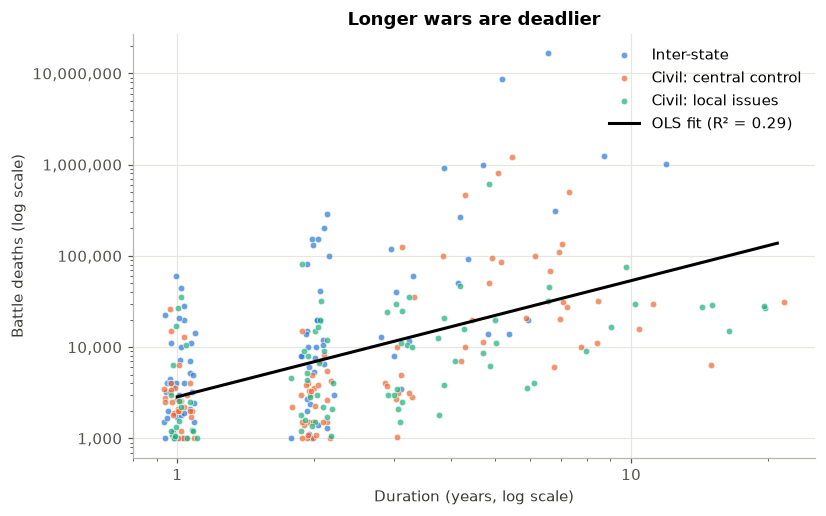

In [10]:
dd = wars.dropna(subset=["log_deaths"])
r, p_r = stats.pearsonr(dd.log_duration, dd.log_deaths)
rho, p_s = stats.spearmanr(dd.duration, dd.deaths)
print(f"Pearson r  (log duration, log deaths) = {r:.3f}   {verdict(p_r)}")
print(f"Spearman ρ (duration, deaths)          = {rho:.3f}   {verdict(p_s)}")
slr = smf.ols("log_deaths ~ log_duration", data=dd).fit()
print(slr.summary().tables[1])
b0, b1 = slr.params
print(f"\nFitted line: log10(deaths) = {b0:.3f} + {b1:.3f}·log10(duration),  R² = {slr.rsquared:.3f}")
print(f"Interpretation: doubling a war's duration multiplies expected deaths by 2^{b1:.2f} = {2**b1:.2f}×")

fig, ax = plt.subplots(figsize=(8, 5))
for col, t in zip(PAL, wars.type.cat.categories):
    s = dd[dd.type == t]
    ax.scatter(s.duration * np.exp(np.random.default_rng(0).normal(0, .05, len(s))), s.deaths, s=18, color=col, alpha=.7,
               edgecolor="white", linewidth=.5, label=t)
xs = np.linspace(0, dd.log_duration.max(), 50)
ax.plot(10**xs, 10**(b0 + b1 * xs), color="black", lw=2, label=f"OLS fit (R² = {slr.rsquared:.2f})")
ax.set(xscale="log", yscale="log", xlabel="Duration (years, log scale)", ylabel="Battle deaths (log scale)",
       title="Longer wars are deadlier")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(); save(fig, "06_duration_vs_deaths")

**Interpretation.** There is a **moderate positive correlation** (r ≈ 0.54, p < 0.001) between log duration and log deaths, so we reject H0. The slope ≈ 1.27 is an *elasticity*: a war that lasts twice as long is expected to kill about 2.4 times as many people. Duration alone explains about 29% of the variation (R² ≈ 0.29), which leaves room for the other predictors in Lab 4. Correlation is not causation here: wars may last longer *because* they are fought at a larger scale.

### (b) Military expenditure vs GDP growth
Military burden = military expenditure (COW, current USD) ÷ GDP (World Bank, current USD), averaged per country over 1960–2016. Real GDP growth comes from Maddison (constant prices). H0: ρ = 0.

151 countries, 7,174 country-years
Pearson r  = 0.193   p = 0.01768 → reject H0 at α = 0.05
Spearman ρ = 0.158   p = 0.05277 → fail to reject H0 at α = 0.05
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.8098      0.269     14.158      0.000       3.278       4.342
burden         0.1470      0.061      2.399      0.018       0.026       0.268
R² = 0.037


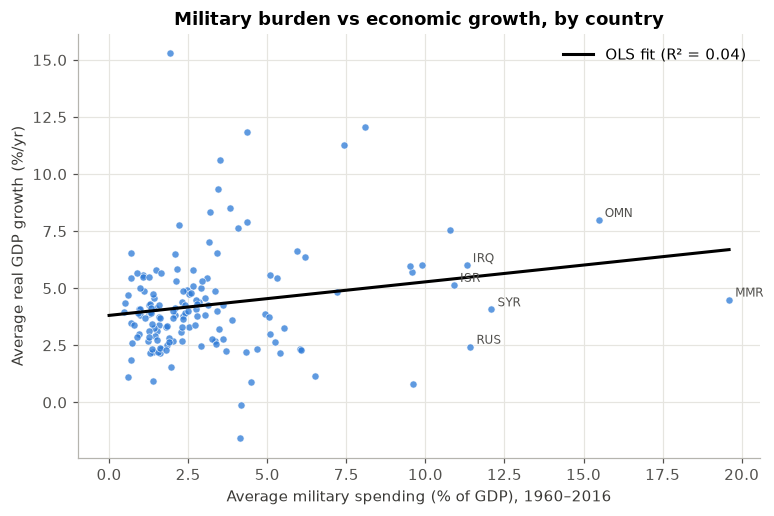

In [11]:
mad = maddison.copy()
mad["iso3"] = coco.convert(mad.Entity.tolist(), to="ISO3", not_found=None)
mad = mad[mad.iso3.map(lambda x: isinstance(x, str))]
keep = mad.groupby(["iso3", "Entity"]).size().reset_index().sort_values(0).drop_duplicates("iso3", keep="last").Entity
mad = mad[mad.Entity.isin(keep)].sort_values(["iso3", "Year"])   # one Maddison series per ISO3 code
mad["growth"] = np.where(mad.groupby("iso3").Year.diff() == 1, mad.groupby("iso3").GDP.pct_change() * 100, np.nan)

milex = nmc[nmc.milex >= 0].assign(iso3=lambda d: d.ccode.map(ccode_iso)).dropna(subset=["iso3"])
panel = (milex[["iso3", "year", "milex"]]
         .merge(wb_gdp.rename(columns={"Country Code": "iso3", "Year": "year", "Value": "gdp_usd"})[["iso3", "year", "gdp_usd"]], on=["iso3", "year"])
         .merge(mad[["iso3", "Year", "growth"]].rename(columns={"Year": "year"}), on=["iso3", "year"]))
panel["burden"] = panel.milex * 1000 / panel.gdp_usd * 100
panel = panel[(panel.burden > 0) & (panel.burden < 50)].dropna()
country = panel.groupby("iso3").agg(burden=("burden", "mean"), growth=("growth", "mean"), years=("year", "count"))
country = country[country.years >= 20]
country.to_csv(CLEAN / "country_military_burden_growth.csv")
print(f"{len(country)} countries, {panel.shape[0]:,} country-years")

r2, p2 = stats.pearsonr(country.burden, country.growth); rho2, ps2 = stats.spearmanr(country.burden, country.growth)
print(f"Pearson r  = {r2:.3f}   {verdict(p2)}")
print(f"Spearman ρ = {rho2:.3f}   {verdict(ps2)}")
slr2 = smf.ols("growth ~ burden", data=country).fit()
print(slr2.summary().tables[1]); print(f"R² = {slr2.rsquared:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(country.burden, country.growth, s=22, color=PAL[0], alpha=.75, edgecolor="white", linewidth=.5)
xs = np.linspace(0, country.burden.max(), 50)
ax.plot(xs, slr2.params.iloc[0] + slr2.params.iloc[1] * xs, color="black", label=f"OLS fit (R² = {slr2.rsquared:.2f})")
for iso in country.nlargest(6, "burden").index:
    ax.annotate(iso, (country.burden[iso], country.growth[iso]), fontsize=8, xytext=(4, 2), textcoords="offset points", color="#52514e")
ax.set(xlabel="Average military spending (% of GDP), 1960–2016", ylabel="Average real GDP growth (%/yr)",
       title="Military burden vs economic growth, by country"); ax.legend(); save(fig, "07_milex_vs_growth")

**Interpretation.** Across 151 countries the correlation between average military burden and average growth is **weak** (Pearson r ≈ 0.19, p ≈ 0.02; Spearman ρ ≈ 0.16, p ≈ 0.05), and R² is under 4%. The Pearson result is significant but driven partly by a few high-spending, fast-growing oil states and East Asian economies; the rank-based Spearman test is borderline. Military spending explains almost nothing about how fast an economy grows.

## Lab 4 · Multiple regression: estimating casualties from war characteristics

Model: log10(deaths) = β0 + β1·log10(duration) + β2·(war type) + β3·(era) + β4·(major power involved) + ε

War type and era are categorical (dummy-coded; baseline = inter-state war, 1816–1899).

In [12]:
mr = smf.ols("log_deaths ~ log_duration + C(type) + C(era) + major_power", data=dd).fit()
print(mr.summary())

X = pd.get_dummies(dd[["log_duration", "type", "era", "major_power"]], drop_first=True).astype(float)
X = sm.add_constant(X)
print("\nVariance inflation factors (VIF < 5 → no serious multicollinearity):")
print(pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:]).round(2).to_string())
print(f"\nAdjusted R²: simple model {slr.rsquared_adj:.3f} → multiple model {mr.rsquared_adj:.3f}")
print("Partial F-test (do the extra predictors add explanatory power?):")
print(sm.stats.anova_lm(slr, mr))
print("\nMultiplicative effects on expected deaths (10^β):")
print((10 ** mr.params).round(2).to_string())

                            OLS Regression Results                            
Dep. Variable:             log_deaths   R-squared:                       0.453
Model:                            OLS   Adj. R-squared:                  0.441
Method:                 Least Squares   F-statistic:                     37.30
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           7.89e-33
Time:                        21:28:12   Log-Likelihood:                -232.53
No. Observations:                 277   AIC:                             479.1
Df Residuals:                     270   BIC:                             504.4
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

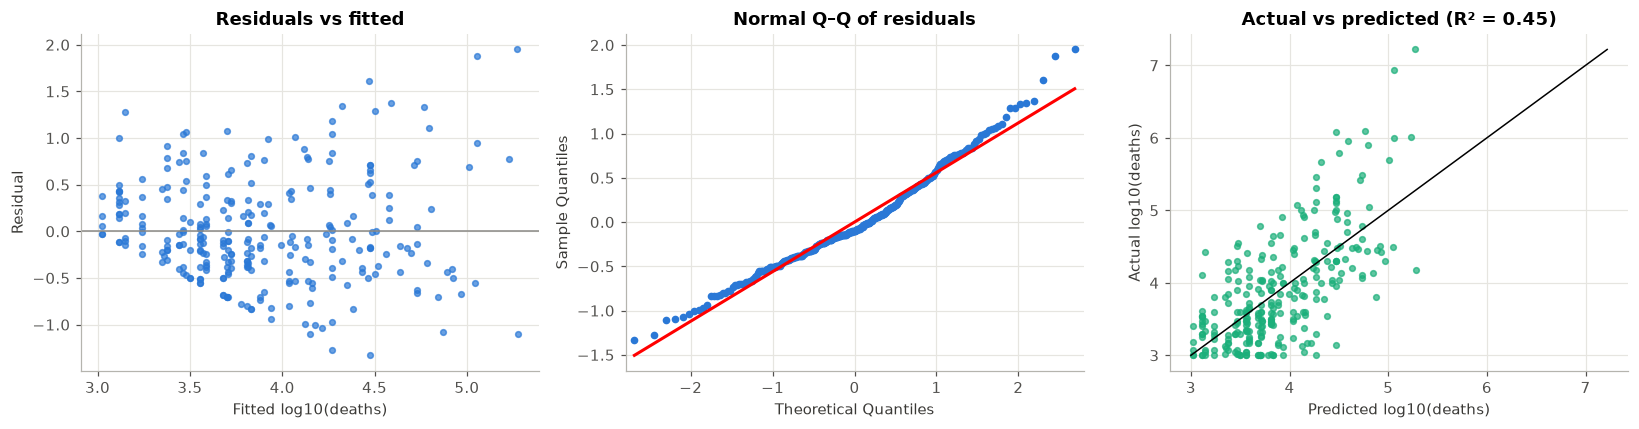

Example: 4-year inter-state war, 1900–1945, with a major power → predicted deaths ≈ 82,215 (95% prediction interval 6,060 – 1,115,443)


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(mr.fittedvalues, mr.resid, s=14, color=PAL[0], alpha=.7); axes[0].axhline(0, color=GRAY, lw=1)
axes[0].set(title="Residuals vs fitted", xlabel="Fitted log10(deaths)", ylabel="Residual")
sm.qqplot(mr.resid, line="s", ax=axes[1], markerfacecolor=PAL[0], markeredgecolor=PAL[0], markersize=4); axes[1].set_title("Normal Q–Q of residuals")
axes[2].scatter(mr.fittedvalues, dd.log_deaths, s=14, color=PAL[2], alpha=.7)
lims = [dd.log_deaths.min(), dd.log_deaths.max()]; axes[2].plot(lims, lims, color="black", lw=1)
axes[2].set(title=f"Actual vs predicted (R² = {mr.rsquared:.2f})", xlabel="Predicted log10(deaths)", ylabel="Actual log10(deaths)")
fig.tight_layout(); save(fig, "08_multiple_regression_diagnostics")

ex = pd.DataFrame({"log_duration": [np.log10(4)], "type": ["Inter-state"], "era": ["1900–1945"], "major_power": [1]})
pr = mr.get_prediction(ex).summary_frame(alpha=.05)
print(f"Example: 4-year inter-state war, 1900–1945, with a major power → predicted deaths ≈ {10**pr['mean'][0]:,.0f} "
      f"(95% prediction interval {10**pr['obs_ci_lower'][0]:,.0f} – {10**pr['obs_ci_upper'][0]:,.0f})")

**Interpretation.**
* The model explains **about 45% of the variance** in log deaths (adjusted R² ≈ 0.44, up from 0.29 with duration alone). The partial F-test confirms the extra predictors add significant explanatory power.
* **Duration** is the strongest predictor (β ≈ 1.46, p < 0.001).
* Holding the other variables fixed, **civil wars** kill roughly 45–55% as many people as inter-state wars (10^β ≈ 0.55 and 0.45).
* Wars that involve a **major power** are about **2.2 times** deadlier (p < 0.001).
* Wars of **1900–1945** are deadlier than 19th-century wars (p ≈ 0.035); post-1945 wars are not significantly different.
* All VIFs are below 2, so multicollinearity is not a concern. The residual Q–Q plot shows heavier tails than normal, so p-values near 0.05 should be read with care.

## Lab 5 · Binomial distribution: historical win/loss proportions

Only participants with a **clearly classified** outcome (Win or Loss) are used; draws, stalemates and transformed wars are excluded.

### (a) Do states that start inter-state wars win them?
Each initiator is a Bernoulli trial (win = success). If initiating gave no advantage, X ~ Binomial(n, 0.5).
H0: p = 0.5 vs H1: p ≠ 0.5.

Initiators with a clear outcome: n = 88, wins k = 61, p̂ = 0.693
Exact binomial test: p = 0.000374 → reject H0 at α = 0.05;  95% Clopper–Pearson CI for p: [0.586, 0.787]

Using p̂ = 0.693:  mean of X for n=10 initiators = 6.93, SD = 1.46
P(exactly 7 of 10 initiators win) = 0.2665
P(at least 7 of 10 initiators win) = 0.6313
P(at least 7 of 10 win) if p were 0.5 = 0.1719


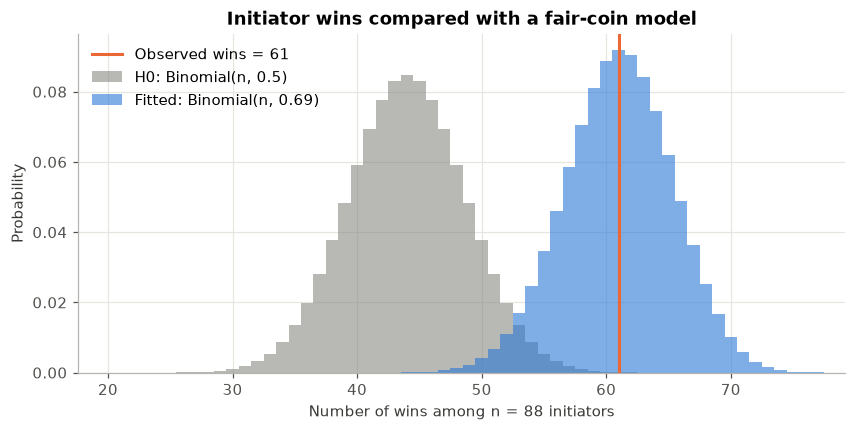

In [14]:
clear = participants[participants.outcome.isin(["Win", "Loss"])]
ini = clear[clear.initiator == 1]
n, k = len(ini), (ini.outcome == "Win").sum()
bt = stats.binomtest(k, n, 0.5)
lo, hi = bt.proportion_ci(method="exact")
print(f"Initiators with a clear outcome: n = {n}, wins k = {k}, p̂ = {k/n:.3f}")
print(f"Exact binomial test: {verdict(bt.pvalue)};  95% Clopper–Pearson CI for p: [{lo:.3f}, {hi:.3f}]")
p_hat = k / n
print(f"\nUsing p̂ = {p_hat:.3f}:  mean of X for n=10 initiators = {10*p_hat:.2f}, SD = {np.sqrt(10*p_hat*(1-p_hat)):.2f}")
print(f"P(exactly 7 of 10 initiators win) = {stats.binom.pmf(7, 10, p_hat):.4f}")
print(f"P(at least 7 of 10 initiators win) = {stats.binom.sf(6, 10, p_hat):.4f}")
print(f"P(at least 7 of 10 win) if p were 0.5 = {stats.binom.sf(6, 10, .5):.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
xs = np.arange(n + 1)
ax.bar(xs, stats.binom.pmf(xs, n, .5), color=GRAY, width=1, alpha=.6, label="H0: Binomial(n, 0.5)")
ax.bar(xs, stats.binom.pmf(xs, n, p_hat), color=PAL[0], width=1, alpha=.6, label=f"Fitted: Binomial(n, {p_hat:.2f})")
ax.axvline(k, color=PAL[1], lw=2, label=f"Observed wins = {k}")
ax.set(xlim=(n * .2, n * .9), xlabel=f"Number of wins among n = {n} initiators", ylabel="Probability",
       title="Initiator wins compared with a fair-coin model"); ax.legend(); save(fig, "09_binomial_initiators")

**Interpretation.** Of 88 initiators with a clear result, 61 won (p̂ ≈ 0.69). Under a fair-coin model, 61 or more wins out of 88 would be extremely unlikely (p < 0.001), so **initiators win significantly more often than chance**. A likely reason is *selection*: states tend to start wars they expect to win.

### (b) Do governments win civil wars?
For civil wars that ended in a clear victory for one side. H0: p(government wins) = 0.5.

In [15]:
cw = intra_wars[intra_wars.outcome.isin(["Government wins", "Rebels win"])]
n2, k2 = len(cw), (cw.outcome == "Government wins").sum()
bt2 = stats.binomtest(k2, n2, .5); lo2, hi2 = bt2.proportion_ci()
print(f"Civil wars with clear outcome: n = {n2}, government wins = {k2}, p̂ = {k2/n2:.3f}")
print(f"Exact binomial test: {verdict(bt2.pvalue)};  95% CI [{lo2:.3f}, {hi2:.3f}]")
print(f"Normal approximation check: np = {n2*.5:.0f} and n(1-p) = {n2*.5:.0f} both ≥ 10 → z-approximation also valid")
z = (k2 - n2 * .5) / np.sqrt(n2 * .25); print(f"z = {z:.2f}, two-sided p = {2*stats.norm.sf(abs(z)):.3g}")

Civil wars with clear outcome: n = 238, government wins = 169, p̂ = 0.710
Exact binomial test: p = 7.333e-11 → reject H0 at α = 0.05;  95% CI [0.648, 0.767]
Normal approximation check: np = 119 and n(1-p) = 119 both ≥ 10 → z-approximation also valid
z = 6.48, two-sided p = 9.05e-11


**Interpretation.** Governments won 71% of civil wars with a decisive outcome (95% CI 65%–77%), significantly more than half. The exact binomial test and the normal approximation agree.

## Lab 6 · Normal and Poisson distributions

### (a) Normal model for log10(battle deaths)
If war deaths are **log-normal**, then log10(deaths) ~ N(μ, σ²). We fit μ and σ, then check the fit with a histogram, a Q–Q plot and formal tests (H0: data come from a normal distribution).

Fitted normal: μ = 3.890, σ = 0.759  (median war ≈ 7,754 deaths)
Shapiro–Wilk W = 0.9006, p = 1.544e-12 → reject H0 at α = 0.05
D'Agostino K² = 64.84, p = 8.331e-15 → reject H0 at α = 0.05
Lilliefors (KS) D = 0.1213, p = 0.001 → reject H0 at α = 0.05
Skewness = 1.256, excess kurtosis = 1.949

Using the normal model to answer probability questions:
  P(deaths >    10,000) model = 0.442   observed share = 0.379
  P(deaths >   100,000) model = 0.072   observed share = 0.083
  P(deaths > 1,000,000) model = 0.003   observed share = 0.018
  Middle 95% of wars: 252 to 238,231 deaths

Contrast — annual real GDP growth 1950–2018 (n = 10,956): skew = -0.39, excess kurtosis = 9.06, D'Agostino p = 0


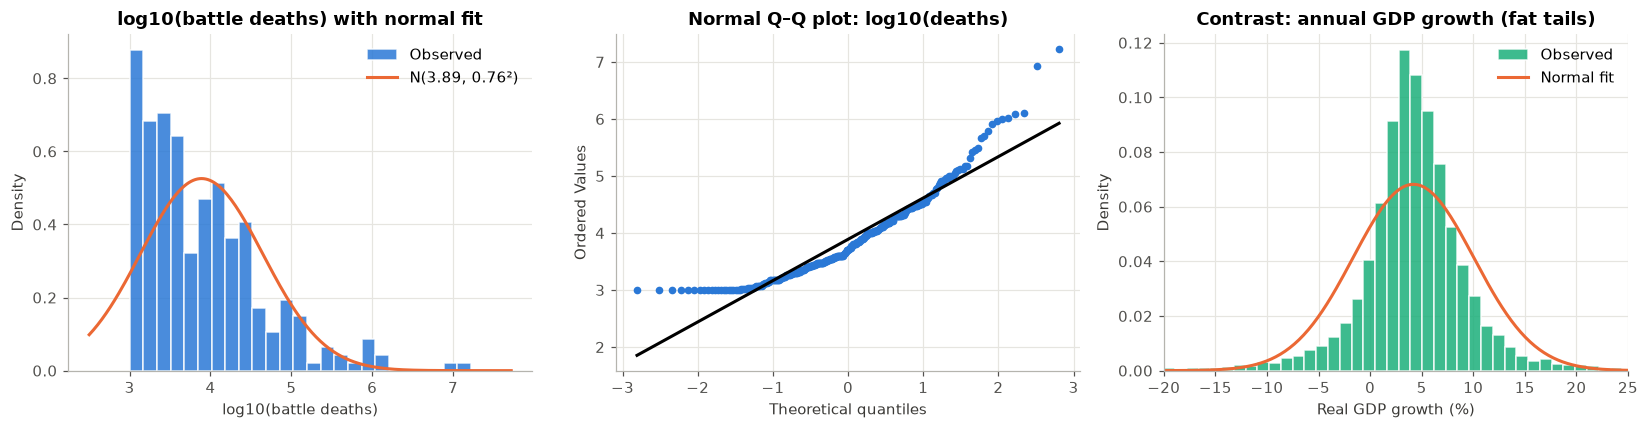

In [16]:
ld = wars.log_deaths.dropna()
mu, sigma = ld.mean(), ld.std()
print(f"Fitted normal: μ = {mu:.3f}, σ = {sigma:.3f}  (median war ≈ {10**mu:,.0f} deaths)")
sw = stats.shapiro(ld); da = stats.normaltest(ld); lf = lilliefors(ld)
print(f"Shapiro–Wilk W = {sw.statistic:.4f}, {verdict(sw.pvalue)}")
print(f"D'Agostino K² = {da.statistic:.2f}, {verdict(da.pvalue)}")
print(f"Lilliefors (KS) D = {lf[0]:.4f}, {verdict(lf[1])}")
print(f"Skewness = {stats.skew(ld):.3f}, excess kurtosis = {stats.kurtosis(ld):.3f}")
print("\nUsing the normal model to answer probability questions:")
for thr in [10_000, 100_000, 1_000_000]:
    model = stats.norm.sf(np.log10(thr), mu, sigma); emp = (ld > np.log10(thr)).mean()
    print(f"  P(deaths > {thr:>9,}) model = {model:.3f}   observed share = {emp:.3f}")
q = stats.norm.ppf([.025, .975], mu, sigma); print(f"  Middle 95% of wars: {10**q[0]:,.0f} to {10**q[1]:,.0f} deaths")

g = maddison.dropna(subset=["GDP"])  # contrast: annual GDP growth
gr = mad[(mad.Year >= 1950)].growth.dropna(); gr = gr[gr.abs() < 50]
print(f"\nContrast — annual real GDP growth 1950–2018 (n = {len(gr):,}): skew = {stats.skew(gr):.2f}, "
      f"excess kurtosis = {stats.kurtosis(gr):.2f}, D'Agostino p = {stats.normaltest(gr).pvalue:.2g}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(ld, bins=25, density=True, color=PAL[0], edgecolor="white", alpha=.85, label="Observed")
xs = np.linspace(ld.min() - .5, ld.max() + .5, 200)
axes[0].plot(xs, stats.norm.pdf(xs, mu, sigma), color=PAL[1], label=f"N({mu:.2f}, {sigma:.2f}²)")
axes[0].set(title="log10(battle deaths) with normal fit", xlabel="log10(battle deaths)", ylabel="Density"); axes[0].legend()
stats.probplot(ld, dist="norm", plot=axes[1]); axes[1].get_lines()[0].set(color=PAL[0], markersize=4); axes[1].get_lines()[1].set(color="black")
axes[1].set_title("Normal Q–Q plot: log10(deaths)")
axes[2].hist(gr, bins=80, density=True, color=PAL[2], edgecolor="white", alpha=.85, label="Observed")
xs = np.linspace(-20, 25, 200); axes[2].plot(xs, stats.norm.pdf(xs, gr.mean(), gr.std()), color=PAL[1], label="Normal fit")
axes[2].set(xlim=(-20, 25), title="Contrast: annual GDP growth (fat tails)", xlabel="Real GDP growth (%)", ylabel="Density"); axes[2].legend()
fig.tight_layout(); save(fig, "10_normal_fit")

**Interpretation.** On a log scale, battle deaths look roughly bell-shaped, and the normal model gives reasonable answers in the middle of the distribution (P(deaths > 100k): model 7.2% vs observed 8.3%). All three formal tests still reject normality. The Q–Q plot shows why: the right tail is **heavier** than a log-normal model allows. The model predicts 0.3% of wars exceed one million deaths, but 1.8% actually do. Rare catastrophic wars are more common than a normal model expects, which matches Richardson's finding that war sizes follow a power law. Annual GDP growth is an even clearer case of a fat-tailed, non-normal variable (excess kurtosis ≈ 9).

### (b) Poisson model for the number of new wars per year
Lewis Fry Richardson (1945) first noticed that war outbreaks look like random, independent events. If so, the number of new inter-state wars starting in a year is X ~ Poisson(λ). A Poisson variable has **mean = variance**, so we check the dispersion index and run a χ² goodness-of-fit test (H0: counts follow Poisson(λ̂)).

Inter-state war onsets per year, 1816–2003 (COW): 188 years, λ̂ = mean = 0.505, variance = 0.476, dispersion index = 0.94


,0,1,2,≥3
observed years,110.000,64.000,12.000,2.000
expected years,113.400,57.300,14.500,2.800


χ² = 1.53, df = 2, p = 0.4659 → fail to reject H0 at α = 0.05

P(no new inter-state war in a year) = e^-λ = 0.603;  P(≥2 new wars) = 0.092
Expected waiting time between onsets = 1/λ = 1.98 years
New armed conflicts per year, 1946+ (UCDP): 72 years, λ̂ = mean = 4.000, variance = 10.732, dispersion index = 2.68


,0,1,2,3,4,5,6,7,8,9,≥10
observed years,4.000,9.000,12.000,14.000,11.000,6.000,7.000,3.000,1.000,0.000,5.000
expected years,1.300,5.300,10.500,14.100,14.100,11.300,7.500,4.300,2.100,1.000,0.600


χ² = 46.67, df = 9, p = 4.525e-07 → reject H0 at α = 0.05



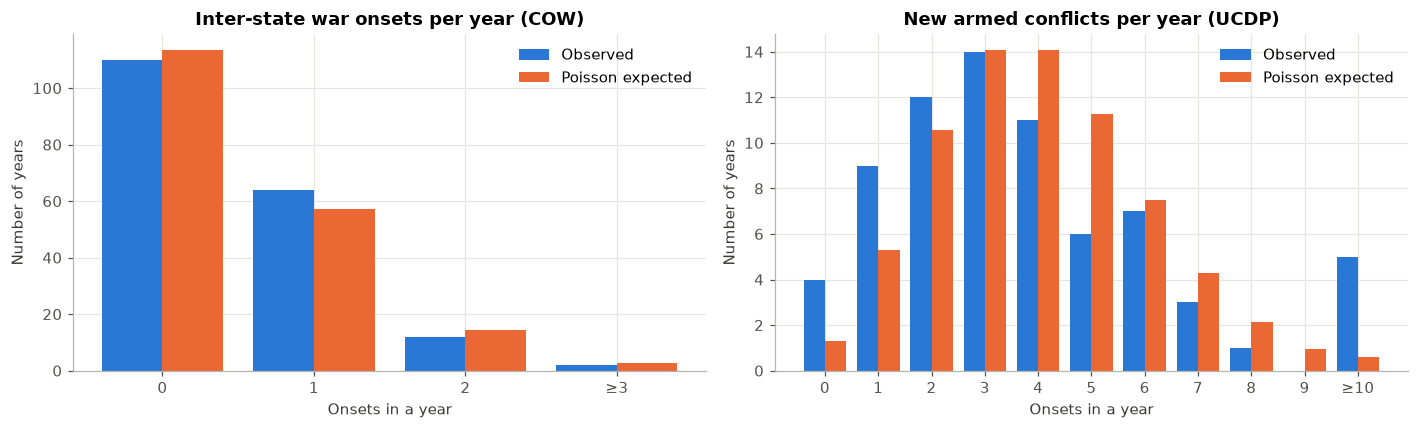

In [17]:
def poisson_gof(counts_per_year, label, merge_from):
    lam = counts_per_year.mean(); var = counts_per_year.var()
    print(f"{label}: {len(counts_per_year)} years, λ̂ = mean = {lam:.3f}, variance = {var:.3f}, dispersion index = {var/lam:.2f}")
    k = np.arange(merge_from)
    obs = np.array([(counts_per_year == i).sum() for i in k] + [(counts_per_year >= merge_from).sum()])
    probs = np.append(stats.poisson.pmf(k, lam), stats.poisson.sf(merge_from - 1, lam))
    exp = probs * len(counts_per_year)
    tab = pd.DataFrame({"observed years": obs, "expected years": exp}, index=[str(i) for i in k] + [f"≥{merge_from}"])
    chi = ((obs - exp) ** 2 / exp).sum(); dof = len(obs) - 1 - 1   # −1 for the estimated λ
    p = stats.chi2.sf(chi, dof)
    display(tab.T.round(1)); print(f"χ² = {chi:.2f}, df = {dof}, {verdict(p)}\n")
    return lam, tab

yrs = pd.Series(0, index=range(1816, 2004))
inter_on = yrs.add(inter_wars.start.value_counts(), fill_value=0).astype(int)
lam, tab = poisson_gof(inter_on, "Inter-state war onsets per year, 1816–2003 (COW)", merge_from=3)
print(f"P(no new inter-state war in a year) = e^-λ = {np.exp(-lam):.3f};  P(≥2 new wars) = {stats.poisson.sf(1, lam):.3f}")
print(f"Expected waiting time between onsets = 1/λ = {1/lam:.2f} years")

ucdp_on = onsets.groupby("year").sumnewconf.sum().astype(int)
lam2, tab2 = poisson_gof(ucdp_on, "New armed conflicts per year, 1946+ (UCDP)", merge_from=10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, t, title in [(axes[0], tab, "Inter-state war onsets per year (COW)"), (axes[1], tab2, "New armed conflicts per year (UCDP)")]:
    x = np.arange(len(t))
    ax.bar(x - .2, t["observed years"], width=.4, color=PAL[0], label="Observed")
    ax.bar(x + .2, t["expected years"], width=.4, color=PAL[1], label="Poisson expected")
    ax.set_xticks(x, t.index); ax.set(title=title, xlabel="Onsets in a year", ylabel="Number of years"); ax.legend()
fig.tight_layout(); save(fig, "11_poisson_fit")

**Interpretation.**
* **Inter-state war onsets fit the Poisson model well.** The mean (0.505) and variance (0.476) are almost equal (dispersion ≈ 0.94), and the χ² goodness-of-fit test does not reject H0 (p ≈ 0.47). This reproduces Richardson's classic result that new wars break out like independent random events, about one every two years.
* **UCDP armed-conflict onsets do *not* fit.** The variance is 2.7 times the mean (*overdispersion*), because onsets cluster in time (for example the early 1990s after the Soviet collapse). A negative binomial model would suit these counts better.

## Lab 7–8 · Hypothesis testing across conflict groups

### (a) Two-proportion z-test: has the government's chance of winning civil wars changed since 1945?
H0: p(before 1946) = p(1946 onwards); H1: they differ.

In [18]:
cw = cw.assign(post45=cw.start >= 1946)
tab_era = cw.groupby("post45").outcome.agg(wins=lambda s: (s == "Government wins").sum(), n="size")
print(tab_era.rename(index={False: "1816–1945", True: "1946–2007"}).assign(share=lambda t: t.wins / t.n))
zstat, pz = proportions_ztest(tab_era.wins.values, tab_era.n.values)
print(f"z = {zstat:.3f}, {verdict(pz)}")

           wins    n  share
post45                     
1816–1945   102  137  0.745
1946–2007    67  101  0.663
z = 1.364, p = 0.1726 → fail to reject H0 at α = 0.05


**Interpretation.** The government win rate dropped from 74.5% before 1946 to 66.3% after, but the difference is not statistically significant (p ≈ 0.17). On its own, this sample cannot rule out chance as the explanation. The chi-square test in Lab 10 shows where the real shift happened: more civil wars now end in compromise.

### (b) Economic indicator by conflict group: GDP growth of winners vs losers during inter-state wars
For each state in an inter-state war (with Maddison data), the mean real GDP growth over the war years. H0: μ_winners = μ_losers.

In [19]:
growth_lookup = mad.set_index(["iso3", "Year"]).growth
def mean_growth(iso, y0, y1, min_years=1):
    vals = [growth_lookup.get((iso, y), np.nan) for y in range(int(y0), int(y1) + 1)]
    vals = [v for v in vals if pd.notna(v)]
    return np.mean(vals) if len(vals) >= min_years else np.nan

part = participants.assign(iso3=participants.ccode.map(ccode_iso)).dropna(subset=["iso3"])
part["war_growth"] = [mean_growth(i, a, b) for i, a, b in zip(part.iso3, part.start, part.end)]
wl = part[part.outcome.isin(["Win", "Loss"])].dropna(subset=["war_growth"])
win_g, loss_g = wl.loc[wl.outcome == "Win", "war_growth"], wl.loc[wl.outcome == "Loss", "war_growth"]
print(f"Winners: n = {len(win_g)}, mean growth = {win_g.mean():.2f}%/yr;  Losers: n = {len(loss_g)}, mean = {loss_g.mean():.2f}%/yr")
t, p = stats.ttest_ind(win_g, loss_g, equal_var=False); print(f"Welch t = {t:.3f}, {verdict(p)}")
u, pu = stats.mannwhitneyu(win_g, loss_g); print(f"Mann–Whitney U = {u:.0f}, {verdict(pu)} (non-parametric check)")

Winners: n = 93, mean growth = 1.38%/yr;  Losers: n = 59, mean = -0.24%/yr
Welch t = 1.101, p = 0.2731 → fail to reject H0 at α = 0.05
Mann–Whitney U = 3061, p = 0.2307 → fail to reject H0 at α = 0.05 (non-parametric check)


**Interpretation.** Winners' economies grew a little faster during wars (+1.4%/yr) than losers' (−0.2%/yr), but the difference is not significant (p ≈ 0.27), so we fail to reject H0. Wartime growth varies too much from country to country to detect a winner/loser gap.

### (c) Economic indicator by conflict group: military burden in war years vs peace years
Country-years 1960–2003: is the state fighting a COW war that year? H0: mean log(military burden) is the same in war and peace years.

In [20]:
war_years = set()
for _, r_ in part.iterrows(): war_years |= {(r_.iso3, y) for y in range(int(r_.start), int(r_.end) + 1)}
civ = intra_wars.dropna(subset=["gov_ccode"]).assign(iso3=lambda d: d.gov_ccode.map(ccode_iso)).dropna(subset=["iso3"])
for _, r_ in civ.iterrows(): war_years |= {(r_.iso3, y) for y in range(int(r_.start), int(r_.end) + 1)}
pn = panel[panel.year <= 2003].copy()
pn["at_war"] = [(i, y) in war_years for i, y in zip(pn.iso3, pn.year)]
pn["log_burden"] = np.log(pn.burden)
print(pn.groupby("at_war").burden.describe()[["count", "mean", "50%", "std"]].rename(index={False: "Peace", True: "War"}))
t, p = stats.ttest_ind(pn.loc[pn.at_war, "log_burden"], pn.loc[~pn.at_war, "log_burden"], equal_var=False)
print(f"Welch t on log burden = {t:.3f}, {verdict(p)}")
print(f"Ratio of geometric means (war/peace) = {np.exp(pn.loc[pn.at_war,'log_burden'].mean() - pn.loc[~pn.at_war,'log_burden'].mean()):.2f}×")

           count  mean   50%   std
at_war                            
Peace  4,528.000 3.333 1.971 4.270
War      521.000 6.647 3.920 6.998
Welch t on log burden = 17.240, p = 3.267e-55 → reject H0 at α = 0.05
Ratio of geometric means (war/peace) = 2.08×


**Interpretation.** Countries spend a much larger share of GDP on the military in years when they are at war (median 3.9% vs 2.0%; geometric means differ by about 2×). The difference is highly significant (Welch t ≈ 17, p < 0.001). Military burden is right-skewed, so the test is run on log(burden).

## Lab 9 · Independent and paired t-tests

### (a) Independent two-sample t-test: internationalised vs purely domestic civil wars
Are civil wars with foreign intervention deadlier? H0: μ(log deaths | internationalised) = μ(log deaths | domestic).

In [21]:
cd_ = wars[wars.type != "Inter-state"].dropna(subset=["log_deaths"])
a, b = cd_.loc[cd_.intnl == 1, "log_deaths"], cd_.loc[cd_.intnl == 0, "log_deaths"]
print(f"Internationalised: n = {len(a)}, mean log10 deaths = {a.mean():.3f} (≈{10**a.mean():,.0f} deaths)")
print(f"Domestic:          n = {len(b)}, mean log10 deaths = {b.mean():.3f} (≈{10**b.mean():,.0f} deaths)")
lev = stats.levene(a, b); print(f"Levene test for equal variances: {verdict(lev.pvalue)}")
ts = stats.ttest_ind(a, b, equal_var=True); tw = stats.ttest_ind(a, b, equal_var=False)
print(f"Student t (pooled) = {ts.statistic:.3f}, {verdict(ts.pvalue)}")
print(f"Welch t            = {tw.statistic:.3f}, {verdict(tw.pvalue)}")
sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
print(f"Cohen's d = {(a.mean() - b.mean())/sp:.2f};  deaths ratio of geometric means = {10**(a.mean()-b.mean()):.2f}×")
ci = tw.confidence_interval(); print(f"95% CI for the difference in mean log10 deaths: [{ci.low:.3f}, {ci.high:.3f}]")

Internationalised: n = 41, mean log10 deaths = 4.198 (≈15,793 deaths)
Domestic:          n = 141, mean log10 deaths = 3.691 (≈4,905 deaths)
Levene test for equal variances: p = 0.1595 → fail to reject H0 at α = 0.05
Student t (pooled) = 4.618, p = 7.36e-06 → reject H0 at α = 0.05
Welch t            = 4.263, p = 7.438e-05 → reject H0 at α = 0.05
Cohen's d = 0.82;  deaths ratio of geometric means = 3.22×
95% CI for the difference in mean log10 deaths: [0.269, 0.746]


**Interpretation.** Levene's test does not reject equal variances, so the pooled Student t-test is appropriate; Welch's version gives the same conclusion. **Internationalised civil wars are significantly deadlier** (p < 0.001): about 3.2 times as many battle deaths on average (geometric mean), with a large effect size (Cohen's d ≈ 0.8). Foreign intervention brings more resources and fighters into a war, and tends to prolong it.

### (b) Paired t-test: pre-war vs wartime GDP growth
Each pair is one country in one war (inter-state participants and governments in civil wars, 1820 onwards where Maddison has data). We compare the country's mean real GDP growth in the **3 years before** the war with its mean growth **during** the war. H0: mean difference (wartime − pre-war) = 0.

380 country-war pairs (203 inter-state, 177 civil)
       pre_war  wartime    diff
count  380.000  380.000 380.000
mean     3.010    0.360  -2.650
std      5.690    9.110   9.460
min    -26.820  -60.190 -49.770
25%      1.320   -1.930  -6.140
50%      3.660    2.270  -1.550
75%      5.710    5.090   1.350
max     20.900   31.290  43.990

Paired t = -5.457, df = 379, p = 8.761e-08 → reject H0 at α = 0.05
Mean change = -2.65 pp, 95% CI [-3.60, -1.69]
Wilcoxon signed-rank (non-parametric check): p = 6.706e-10 → reject H0 at α = 0.05
Share of pairs where growth fell during the war: 64.2%
  Civil        n = 177, mean change =  -2.61 pp, p = 0.0006145 → reject H0 at α = 0.05
  Inter-state  n = 203, mean change =  -2.68 pp, p = 3.537e-05 → reject H0 at α = 0.05


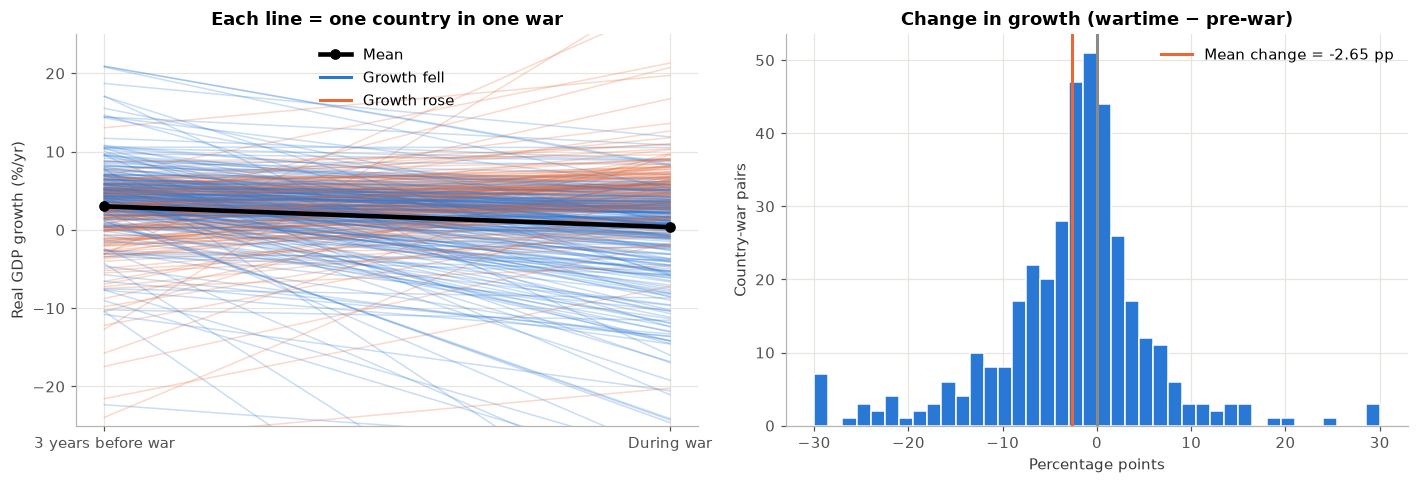

In [22]:
rows = []
for _, r_ in part.iterrows():
    rows.append(("Inter-state", r_.warnum, r_.iso3, r_.start, r_.end))
for _, r_ in civ.iterrows():
    rows.append(("Civil", r_.warnum, r_.iso3, r_.start, r_.end))
pairs = pd.DataFrame(rows, columns=["kind", "warnum", "iso3", "start", "end"])
pairs["pre_war"] = [mean_growth(i, s - 3, s - 1, min_years=2) for i, s in zip(pairs.iso3, pairs.start)]
pairs["wartime"] = [mean_growth(i, s, e) for i, s, e in zip(pairs.iso3, pairs.start, pairs.end)]
pairs = pairs.dropna(subset=["pre_war", "wartime"]); pairs["diff"] = pairs.wartime - pairs.pre_war
pairs.to_csv(CLEAN / "paired_gdp_growth.csv", index=False)
print(f"{len(pairs)} country-war pairs ({(pairs.kind=='Inter-state').sum()} inter-state, {(pairs.kind=='Civil').sum()} civil)")
print(pairs[["pre_war", "wartime", "diff"]].describe().round(2))
tp = stats.ttest_rel(pairs.wartime, pairs.pre_war)
print(f"\nPaired t = {tp.statistic:.3f}, df = {len(pairs)-1}, {verdict(tp.pvalue)}")
ci = tp.confidence_interval(); print(f"Mean change = {pairs['diff'].mean():.2f} pp, 95% CI [{ci.low:.2f}, {ci.high:.2f}]")
wx = stats.wilcoxon(pairs.wartime, pairs.pre_war); print(f"Wilcoxon signed-rank (non-parametric check): {verdict(wx.pvalue)}")
print(f"Share of pairs where growth fell during the war: {(pairs['diff'] < 0).mean():.1%}")
for kname, g_ in pairs.groupby("kind"):
    t_ = stats.ttest_rel(g_.wartime, g_.pre_war)
    print(f"  {kname:12s} n = {len(g_):3d}, mean change = {g_['diff'].mean():6.2f} pp, {verdict(t_.pvalue)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for _, r_ in pairs.iterrows():
    axes[0].plot([0, 1], [r_.pre_war, r_.wartime], color=PAL[0] if r_["diff"] < 0 else PAL[1], alpha=.25, lw=1)
axes[0].plot([0, 1], [pairs.pre_war.mean(), pairs.wartime.mean()], color="black", lw=3, marker="o", label="Mean")
axes[0].plot([], [], color=PAL[0], label="Growth fell"); axes[0].plot([], [], color=PAL[1], label="Growth rose")
axes[0].set_xticks([0, 1], ["3 years before war", "During war"]); axes[0].set_ylim(-25, 25)
axes[0].set(ylabel="Real GDP growth (%/yr)", title="Each line = one country in one war"); axes[0].legend()
axes[1].hist(pairs["diff"].clip(-30, 30), bins=40, color=PAL[0], edgecolor="white"); axes[1].axvline(0, color=GRAY)
axes[1].axvline(pairs["diff"].mean(), color=PAL[1], lw=2, label=f"Mean change = {pairs['diff'].mean():.2f} pp")
axes[1].set(title="Change in growth (wartime − pre-war)", xlabel="Percentage points", ylabel="Country-war pairs"); axes[1].legend()
fig.tight_layout(); save(fig, "12_paired_gdp_growth")

**Interpretation.** Across 380 country-war pairs, real GDP growth falls by an average of **2.65 percentage points** during war compared with the three years before it (95% CI −3.6 to −1.7; paired t ≈ −5.5, p < 0.001), so we reject H0. The non-parametric Wilcoxon test agrees, and the drop is similar for inter-state and civil wars. Growth fell in about two out of three cases. The rest are mostly states fighting far from home, such as the USA in World War II, whose economy boomed.

The **paired** design matters here: each country is compared with itself, which removes the large differences in baseline growth *between* countries.

## Lab 10 · Chi-square test of independence

### (a) Civil-war type × outcome
H0: the outcome of a civil war is independent of whether it was fought over central control of the state or over local issues (secession/autonomy).

In [23]:
def chi_square_report(table, title):
    chi2, p, dof, exp = stats.chi2_contingency(table)
    print(title); display(table)
    print("Expected counts under H0:"); display(pd.DataFrame(exp, index=table.index, columns=table.columns).round(1))
    print(f"χ² = {chi2:.2f}, df = {dof}, {verdict(p)};  min expected count = {exp.min():.1f}")
    V = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))); print(f"Cramér's V = {V:.3f}")
    resid = (table - exp) / np.sqrt(exp); print("Standardised (Pearson) residuals (|r| > 2 drives the result):"); display(resid.round(2))
    return chi2, p

civil = wars[wars.type != "Inter-state"].copy()
civil["outcome3"] = civil.outcome.replace({"Compromise": "Compromise / other", "Other / unresolved": "Compromise / other"})
t1 = pd.crosstab(civil.type.astype(str), civil.outcome3)
chi_square_report(t1, "Civil-war type × outcome")

Civil-war type × outcome


outcome3,Compromise / other,Government wins,Rebels win
type,,,
Civil: central control,33,87,54
Civil: local issues,35,82,15


Expected counts under H0:


outcome3,Compromise / other,Government wins,Rebels win
type,,,
Civil: central control,38.700,96.100,39.200
Civil: local issues,29.300,72.900,29.800


χ² = 16.80, df = 2, p = 0.0002246 → reject H0 at α = 0.05;  min expected count = 29.3
Cramér's V = 0.234
Standardised (Pearson) residuals (|r| > 2 drives the result):


outcome3,Compromise / other,Government wins,Rebels win
type,,,
Civil: central control,-0.910,-0.930,2.360
Civil: local issues,1.050,1.070,-2.710


(np.float64(16.802057315882134), np.float64(0.00022463613154959832))

**Interpretation.** Outcome depends on the type of civil war (χ² ≈ 16.8, df = 2, p < 0.001; Cramér's V ≈ 0.23, a moderate association). The standardised residuals show that **rebels win far more often when fighting for control of the central government** than in secessionist or local wars (residuals +2.4 vs −2.7). Separatist rebels rarely defeat the state outright. All expected counts are above 5, so the χ² approximation is valid.

### (b) Era × civil-war outcome

In [24]:
t2 = pd.crosstab(civil.era, civil.outcome3)
chi_square_report(t2, "Era × civil-war outcome")

Era × civil-war outcome


outcome3,Compromise / other,Government wins,Rebels win
era,,,
1816–1899,8,64,26
1900–1945,5,38,9
1946–2007,55,67,34


Expected counts under H0:


outcome3,Compromise / other,Government wins,Rebels win
era,,,
1816–1899,21.800,54.100,22.100
1900–1945,11.600,28.700,11.700
1946–2007,34.700,86.200,35.200


χ² = 34.78, df = 4, p = 5.144e-07 → reject H0 at α = 0.05;  min expected count = 11.6
Cramér's V = 0.238
Standardised (Pearson) residuals (|r| > 2 drives the result):


outcome3,Compromise / other,Government wins,Rebels win
era,,,
1816–1899,-2.950,1.340,0.830
1900–1945,-1.930,1.730,-0.800
1946–2007,3.450,-2.060,-0.200


(np.float64(34.78454385850836), np.float64(5.143605507943336e-07))

**Interpretation.** Outcome is also associated with era (χ² ≈ 34.8, df = 4, p < 0.001). The largest residual is **compromise / other outcomes after 1945** (+3.45). Since the Second World War, many more civil wars end in negotiated settlements or unresolved stalemate rather than outright victory.

### (c) Initiator × win/loss in inter-state wars (2×2), with Fisher's exact test as a check

Initiator status × outcome


outcome,Loss,Win
initiator,,
Initiator,27,61
Target,91,90


Expected counts under H0:


outcome,Loss,Win
initiator,,
Initiator,38.600,49.400
Target,79.400,101.600


χ² = 8.45, df = 1, p = 0.003643 → reject H0 at α = 0.05;  min expected count = 38.6
Cramér's V = 0.177
Standardised (Pearson) residuals (|r| > 2 drives the result):


outcome,Loss,Win
initiator,,
Initiator,-1.870,1.650
Target,1.300,-1.150


Fisher exact test: odds ratio = 0.44, p = 0.002603 → reject H0 at α = 0.05


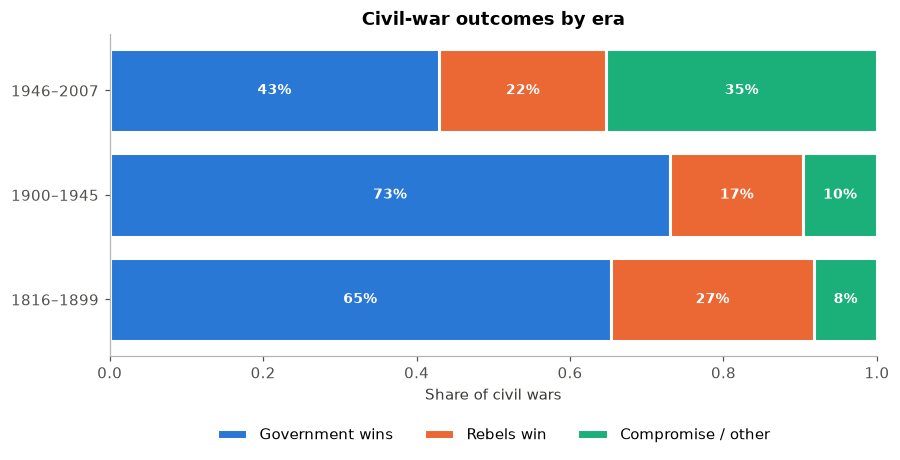

In [25]:
t3 = pd.crosstab(clear.initiator.map({1: "Initiator", 0: "Target"}), clear.outcome)
chi_square_report(t3, "Initiator status × outcome")
print(f"Fisher exact test: odds ratio = {stats.fisher_exact(t3).statistic:.2f}, {verdict(stats.fisher_exact(t3).pvalue)}")

fig, ax = plt.subplots(figsize=(9, 3.8))
share = pd.crosstab(civil.era, civil.outcome3, normalize="index")
left = np.zeros(len(share))
for col, cname in zip(PAL, ["Government wins", "Rebels win", "Compromise / other"]):
    ax.barh(share.index.astype(str), share[cname], left=left, color=col, label=cname, edgecolor="white", linewidth=2)
    for y, (l, w) in enumerate(zip(left, share[cname])):
        if w > .06: ax.text(l + w / 2, y, f"{w:.0%}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += share[cname].values
ax.set(xlim=(0, 1), xlabel="Share of civil wars", title="Civil-war outcomes by era"); ax.grid(False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.18)); save(fig, "13_chisq_outcomes_by_era")

**Interpretation (2×2).** Initiator status and outcome are associated (χ² ≈ 8.5, p ≈ 0.004; Fisher's exact p ≈ 0.003). Targets have about 0.44 times the odds of winning that initiators have. This confirms the binomial result from Lab 5 with a different test.

## Lab 11 · One-way ANOVA: mean log-casualties across three war types

Groups: inter-state wars, civil wars over central control, civil wars over local issues.
H0: μ1 = μ2 = μ3 (all three war types have the same mean log10 deaths); H1: at least one mean differs.

In [26]:
grp = {t: dd.loc[dd.type == t, "log_deaths"] for t in dd.type.cat.categories}
print(pd.DataFrame({t: [len(g), g.mean(), g.std(), 10**g.mean()] for t, g in grp.items()},
                   index=["n", "mean log10 deaths", "SD", "geometric-mean deaths"]).T.round(3))
lev = stats.levene(*grp.values()); print(f"\nLevene test (equal variances): {verdict(lev.pvalue)}")
aov = smf.ols("log_deaths ~ C(type)", data=dd).fit()
table = sm.stats.anova_lm(aov, typ=2); print("\nANOVA table:"); print(table)
ss = table["sum_sq"]; print(f"η² (share of variance explained by war type) = {ss.iloc[0]/ss.sum():.3f}")
print(f"Shapiro–Wilk on ANOVA residuals: {verdict(stats.shapiro(aov.resid).pvalue)}")
w = anova_oneway(dd.log_deaths, dd.type.astype(str), use_var="unequal"); print(f"Welch ANOVA (robust to unequal variances): F = {w.statistic:.2f}, {verdict(w.pvalue)}")
kw = stats.kruskal(*grp.values()); print(f"Kruskal–Wallis (non-parametric): H = {kw.statistic:.2f}, {verdict(kw.pvalue)}")
print("\nTukey HSD post-hoc comparisons:")
print(pairwise_tukeyhsd(dd.log_deaths, dd.type.astype(str)).summary())

                            n  mean log10 deaths    SD  geometric-mean deaths
Inter-state            95.000              4.051 0.910             11,258.099
Civil: central control 99.000              3.800 0.711              6,303.905
Civil: local issues    83.000              3.811 0.582              6,478.125

Levene test (equal variances): p = 0.02413 → reject H0 at α = 0.05

ANOVA table:
          sum_sq      df     F  PR(>F)
C(type)    3.798   2.000 3.353   0.036
Residual 155.169 274.000   NaN     NaN
η² (share of variance explained by war type) = 0.024
Shapiro–Wilk on ANOVA residuals: p = 6.401e-11 → reject H0 at α = 0.05
Welch ANOVA (robust to unequal variances): F = 2.74, p = 0.06752 → fail to reject H0 at α = 0.05
Kruskal–Wallis (non-parametric): H = 3.50, p = 0.1736 → fail to reject H0 at α = 0.05

Tukey HSD post-hoc comparisons:
              Multiple Comparison of Means - Tukey HSD, FWER=0.05               
        group1                group2       meandiff p-adj   lower  u

**Interpretation.** The classical one-way ANOVA rejects H0 (F ≈ 3.35, p ≈ 0.036), with inter-state wars deadliest (geometric mean ≈ 11,000 deaths vs ≈ 6,300–6,500 for civil wars). However:
* Levene's test shows the variances are **not equal** (inter-state wars vary much more), and the residuals are not normal.
* The robust **Welch ANOVA** (p ≈ 0.068) and the non-parametric **Kruskal–Wallis** test (p ≈ 0.17) do *not* reject H0.
* Tukey's HSD finds no single pair significantly different at the 5% family-wise level; inter-state vs central-control civil wars is closest (p ≈ 0.053).

**Conclusion:** the evidence that the three war types differ in mean log-casualties is *weak and sensitive to the ANOVA's assumptions*. Checking assumptions before trusting an F-test is the main lesson of this section. The multiple regression in Lab 4 did find a clear type effect once duration was held constant, because inter-state and civil wars of the *same length* differ more than the raw groups do.

### Two-way ANOVA extension: war type × era

                sum_sq      df     F  PR(>F)
C(type)          2.749   2.000 2.480   0.086
C(era)           5.239   2.000 4.726   0.010
C(type):C(era)   1.376   4.000 0.621   0.648
Residual       148.554 268.000   NaN     NaN


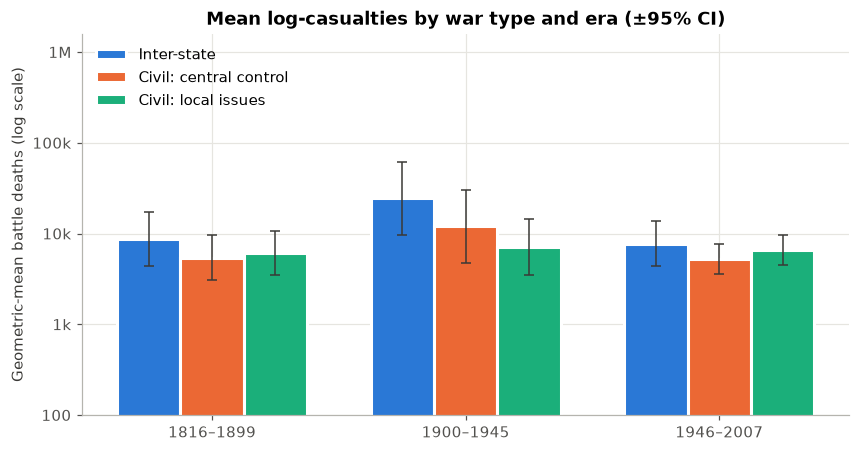

In [27]:
aov2 = smf.ols("log_deaths ~ C(type) * C(era)", data=dd).fit()
print(sm.stats.anova_lm(aov2, typ=2))

fig, ax = plt.subplots(figsize=(9, 4.5))
cats = list(dd.type.cat.categories)
m_ = dd.groupby(["era", "type"], observed=True).log_deaths.agg(["mean", "sem"]).reset_index()
for j, (col, t) in enumerate(zip(PAL, cats)):
    s = m_[m_.type == t]
    xpos = np.arange(len(s)) + (j - 1) * .25
    ax.bar(xpos, s["mean"], width=.25, color=col, label=t, edgecolor="white", linewidth=2)
    ax.errorbar(xpos, s["mean"], yerr=1.96 * s["sem"], fmt="none", ecolor="#3a3936", capsize=3, lw=1)
ax.set_xticks(range(3), dd.era.cat.categories); ax.set_ylim(2, 6.2)
ax.set_yticks(range(2, 7), ["100", "1k", "10k", "100k", "1M"])
ax.set(ylabel="Geometric-mean battle deaths (log scale)", title="Mean log-casualties by war type and era (±95% CI)")
ax.legend(loc="upper left"); save(fig, "14_anova_means")

**Interpretation.** In the two-way model, **era** has a significant main effect (p ≈ 0.01; the 1900–1945 world-war era was deadliest), war type is marginal (p ≈ 0.09), and there is no significant interaction (p ≈ 0.65). The gap between war types is about the same in every era.

## Summary of results

| Lab | Test | Result | Decision (α = 0.05) |
|---|---|---|---|
| 1–2 | Descriptive statistics | 401 wars; mean duration 3.1 yrs; deaths extremely right-skewed (median ≈ 7,000) | — |
| 3 | Pearson correlation, OLS: log duration → log deaths | r ≈ 0.54, slope ≈ 1.27, R² ≈ 0.29 | Reject H0: positive association |
| 3 | Pearson / Spearman: military burden vs GDP growth | r ≈ 0.19 (p ≈ 0.02), ρ ≈ 0.16 (p ≈ 0.05), R² < 0.04 | Weak; borderline |
| 4 | Multiple regression on log deaths | Adj. R² ≈ 0.44; duration, war type, major power, era all significant | Model significant |
| 5 | Exact binomial: initiators win? | 61/88 = 69% | Reject p = 0.5 |
| 5 | Exact binomial: governments win civil wars? | 169/238 = 71% | Reject p = 0.5 |
| 6 | Normality of log deaths (Shapiro–Wilk, K², Lilliefors) | Rejected; right tail heavier than log-normal | Reject normality |
| 6 | Poisson GOF: inter-state war onsets per year | λ ≈ 0.51, dispersion 0.94, χ² p ≈ 0.47 | Fail to reject: Poisson fits |
| 6 | Poisson GOF: UCDP conflict onsets | dispersion 2.7, χ² p < 0.001 | Reject: overdispersed |
| 7–8 | Two-proportion z: government win rate pre vs post 1945 | 74.5% vs 66.3%, p ≈ 0.17 | Fail to reject |
| 7–8 | Welch t: wartime growth, winners vs losers | +1.4% vs −0.2%, p ≈ 0.27 | Fail to reject |
| 7–8 | Welch t: military burden, war vs peace years | 2.1× higher at war, p < 0.001 | Reject |
| 9 | Independent t: internationalised vs domestic civil wars | 3.2× deadlier, d ≈ 0.8, p < 0.001 | Reject |
| 9 | Paired t: pre-war vs wartime GDP growth | −2.65 pp, p < 0.001 (n = 380) | Reject |
| 10 | χ²: civil-war type × outcome | χ² ≈ 16.8, V ≈ 0.23, p < 0.001 | Reject independence |
| 10 | χ²: era × civil-war outcome | χ² ≈ 34.8, p < 0.001 | Reject independence |
| 10 | χ² / Fisher: initiator × win | p ≈ 0.004 | Reject independence |
| 11 | One-way ANOVA: log deaths by 3 war types | F p ≈ 0.036; Welch p ≈ 0.07; Kruskal p ≈ 0.17 | Weak evidence; sensitive to assumptions |

**Limitations.** COW records battle deaths only (not civilian deaths), and death totals for many 19th-century civil wars are missing (277 of 401 wars have a usable total). Duration is measured in calendar years, which is coarse for short wars. GDP data before 1950 cover only about 60 countries. Historical states are matched to their modern successors for the map and the GDP data.

**References.** Sarkees & Wayman (2010), *Resort to War*, CQ Press (COW war data) · Gleditsch et al. (2002), "Armed Conflict 1946–2001", *Journal of Peace Research* (UCDP/PRIO) · Bolt & van Zanden (2020), Maddison Project Database · Singer, Bremer & Stuckey (1972), National Material Capabilities · Miller (2022), "peacesciencer", *Conflict Management and Peace Science* · Richardson (1945), "The distribution of wars in time", *JRSS*.